# B안 샴푸 데이터 감사: 원본 검증 · 구조 점검 · 시각화

이 노트북은 Chitre et al. 공개 샴푸 데이터의 **원본을 수정하지 않고** 다음을 재현합니다.

1. 출처 기록의 SHA-256과 원본 JSON을 대조합니다.
2. 처방 1건을 관측 단위로 하여 필드 충족률과 데이터 구조를 집계합니다.
3. 안정성 라벨 분포와 처방 조성의 복잡도를 시각화합니다.

이 단계는 모델 학습, 결측 대치, 조성 재정규화, skin/eye 데이터 병합을 하지 않습니다. 수치 0과 결측은 분리해 유지합니다.

## 실행 방법

저장소 루트에서 이 파일을 Jupyter 또는 VS Code로 열고 위에서 아래 순서로 실행합니다. 생성물은 `shampoo_demo/results/data_audit/`에만 저장됩니다.

In [1]:
# %% Imports and paths
from __future__ import annotations

import csv
import hashlib
import json
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
from IPython.display import Image, display

# This notebook lives in shampoo_demo/src, so its parent is shampoo_demo.
DEMO = Path.cwd() / 'shampoo_demo' if (Path.cwd() / 'shampoo_demo').exists() else Path.cwd().parent
RAW = DEMO / 'data' / 'liquid_formulations' / 'LiquidFormulationsDataset_2023.json'
REFERENCE = DEMO / 'data' / 'ingredient_reference' / 'surfactants' / 'BASF Surfactants Information.csv'
PROVENANCE = DEMO / 'docs' / 'sources' / 'provenance.json'
OUT = DEMO / 'results' / 'data_audit'
FIG = OUT / 'figures'
OUTCOME_COLUMNS = {'ID', 'Stability_Test', 'Turbidity_NTU', 'Turbidity_Error', 'Viscosity', 'Rheology_Type', 'Rheology_Data'}
print(f'Raw data: {RAW}')

Raw data: C:\Users\DS\COS\repository\shampoo_demo\data\liquid_formulations\LiquidFormulationsDataset_2023.json


In [2]:
# %% Strict, read-only parsing helpers
def sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as source:
        for block in iter(lambda: source.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest().upper()

def no_duplicates(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f'Duplicate JSON key: {key!r}')
        result[key] = value
    return result

def reject_constant(token: str) -> None:
    raise ValueError(f'Non-standard JSON constant: {token}')

def load_json(path: Path) -> Any:
    with path.open(encoding='utf-8') as source:
        return json.load(source, object_pairs_hook=no_duplicates, parse_constant=reject_constant)

def expected_hash(provenance: dict[str, Any], relative_path: str) -> str:
    matches = [item for item in provenance.get('sources', []) if item.get('path') == relative_path]
    if len(matches) != 1:
        raise KeyError(f'Expected exactly one provenance record for {relative_path}')
    return matches[0]['sha256'].upper()

In [3]:
# %% Load and verify source before inspecting it
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
source_hash = sha256(RAW)
provenance = load_json(PROVENANCE)
assert source_hash == expected_hash(provenance, 'data/liquid_formulations/LiquidFormulationsDataset_2023.json'), 'SHA-256 mismatch: stop and inspect the source.'
records = load_json(RAW)
assert isinstance(records, list) and all(isinstance(row, dict) for row in records)
print(f'PASS — {len(records)} formulation records; SHA-256 verified.')

PASS — 812 formulation records; SHA-256 verified.


In [4]:
# %% Aggregate schema and field mapping (never export raw rows or IDs)
def type_name(value: Any) -> str:
    if value is None: return 'null'
    if isinstance(value, bool): return 'bool'
    if isinstance(value, (int, float)): return 'number'
    if isinstance(value, str): return 'string'
    if isinstance(value, list): return 'list'
    if isinstance(value, dict): return 'object'
    return type(value).__name__

def count_scalar_paths(value: Any, path: str, counts: Counter[str]) -> None:
    if isinstance(value, dict):
        for key, child in value.items():
            count_scalar_paths(child, f'{path}.{key}' if path else key, counts)
    elif isinstance(value, list):
        first_type = type_name(value[0]) if value else 'empty'
        counts[f'{path}[]<{first_type}>'] += 1
    else:
        counts[path] += 1

top_fields, scalar_paths = Counter(), Counter()
for record in records:
    top_fields.update(record.keys())
    count_scalar_paths(record, '', scalar_paths)

ingredient_columns = sorted(key for key in records[0] if key not in OUTCOME_COLUMNS)
assert len(ingredient_columns) == 18, f'Expected 18 formulation input columns, found {len(ingredient_columns)}'
with REFERENCE.open(newline='', encoding='utf-8-sig') as source:
    reference_columns = [row['trade_name'].replace('®', '').strip() for row in csv.DictReader(source)]
assert set(reference_columns).issubset(ingredient_columns)
print(f'Input mapping: {len(ingredient_columns)} formulation inputs; {len(reference_columns)} are documented in the surfactant reference CSV.')

Input mapping: 18 formulation inputs; 12 are documented in the surfactant reference CSV.


In [5]:
# %% Derive only aggregate labels and composition counts
stability = Counter(str(record['Stability_Test']).strip() for record in records if record['Stability_Test'] is not None)
nonzero_per_formula, usage, missing = [], Counter({column: 0 for column in ingredient_columns}), Counter()
for record in records:
    used = 0
    for column in ingredient_columns:
        value = record[column]
        if value is None:
            missing[column] += 1
        elif isinstance(value, (int, float)) and value > 0:
            used += 1
            usage[column] += 1
        elif not isinstance(value, (int, float)):
            raise TypeError(f'Non-numeric input in {column!r}')
    nonzero_per_formula.append(used)
print('Stability labels:', dict(stability))
print('Missing ingredient values:', sum(missing.values()))

Stability labels: {'False': 518, 'True': 294}
Missing ingredient values: 0


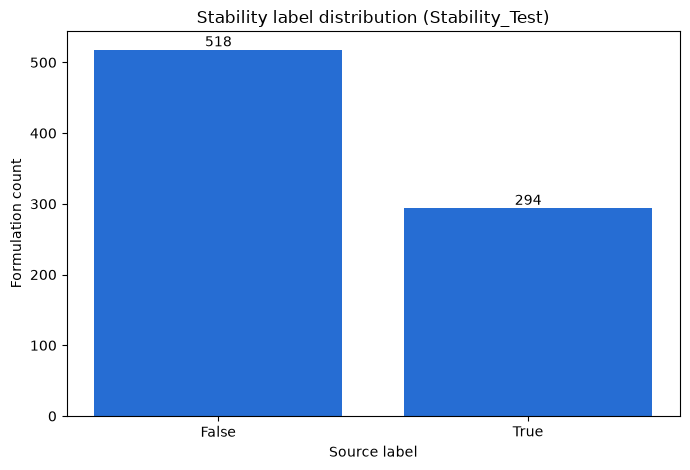

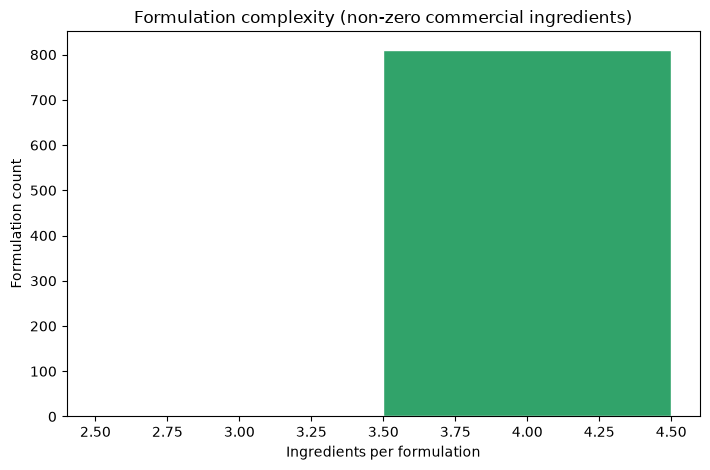

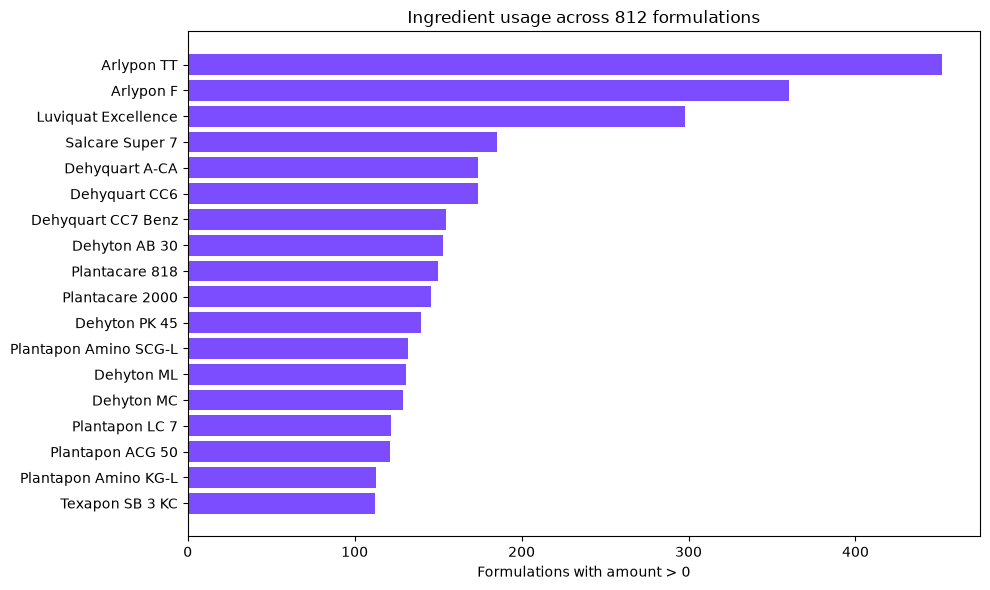

In [6]:
# %% Visualize what is useful for later modelling decisions
labels, values = zip(*sorted(stability.items(), key=lambda item: (-item[1], item[0])))
fig, ax = plt.subplots(figsize=(7, 4.8))
bars = ax.bar(labels, values, color='#266DD3')
ax.set(title='Stability label distribution (Stability_Test)', xlabel='Source label', ylabel='Formulation count')
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, value, str(value), ha='center', va='bottom')
fig.tight_layout(); fig.savefig(FIG / 'stability_label_distribution.png', dpi=180); plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.hist(nonzero_per_formula, bins=range(min(nonzero_per_formula), max(nonzero_per_formula)+2), color='#31A36A', edgecolor='white', align='left')
ax.set(title='Formulation complexity (non-zero commercial ingredients)', xlabel='Ingredients per formulation', ylabel='Formulation count')
fig.tight_layout(); fig.savefig(FIG / 'ingredients_per_formulation.png', dpi=180); plt.show()

names, counts = zip(*sorted(usage.items(), key=lambda item: (-item[1], item[0])))
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(names)), counts, color='#7C4DFF')
ax.set(yticks=range(len(names)), yticklabels=names, xlabel='Formulations with amount > 0', title='Ingredient usage across 812 formulations')
ax.invert_yaxis(); fig.tight_layout(); fig.savefig(FIG / 'ingredient_usage_frequency.png', dpi=180); plt.show()

In [7]:
# %% Save reviewable aggregate outputs for GitHub
schema = {
    'observational_unit': 'one shampoo formulation in the source JSON',
    'record_count': len(records), 'raw_sha256': source_hash,
    'top_level_field_counts': dict(sorted(top_fields.items())),
    'nested_scalar_path_counts': dict(sorted(scalar_paths.items())),
    'automatic_field_mapping': {'stability': 'Stability_Test', 'wide_ingredient_columns': ingredient_columns, 'reference_csv_surfactant_columns': reference_columns},
    'wide_ingredient_missing_counts': dict(missing),
}
(OUT / 'schema_summary.json').write_text(json.dumps(schema, ensure_ascii=False, indent=2), encoding='utf-8')
with (OUT / 'field_completeness.csv').open('w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file); writer.writerow(['top_level_field', 'present_records', 'total_records', 'completeness'])
    for key, count in sorted(top_fields.items(), key=lambda item: (-item[1], item[0])):
        writer.writerow([key, count, len(records), f'{count / len(records):.6f}'])
report = ['# Shampoo raw-data audit', '', f'- Generated (UTC): {datetime.now(timezone.utc).isoformat()}', '- Observational unit: one shampoo formulation in the source JSON', f'- Parsed formulations: {len(records)}', f'- Raw SHA-256: `{source_hash}`', '- Provenance hash check: **PASS**', '', '## Safeguards', '', '- Raw input is read-only; no row deletion, imputation, or composition renormalization occurred.', '- Numeric zero and an absent field remain distinct.', '- No split, threshold selection, or predictive performance result is produced here.', '', '## Automatic mapping candidates', '', '- Stability: `Stability_Test`', '- Inputs: 18 wide numeric formulation columns after excluding seven documented outcomes/metadata columns.', f'- BASF reference CSV: {len(reference_columns)} documented surfactant columns; the other six composition inputs are retained.', '- Figures: `figures/stability_label_distribution.png`, `figures/ingredients_per_formulation.png`, `figures/ingredient_usage_frequency.png`.', '', '## Next decision', '', 'Confirm mappings for stability, turbidity, viscosity, ingredient identity, and input quantity. Then define formulation-combination groups before group-aware model evaluation.', '']
(OUT / 'audit_summary.md').write_text('\n'.join(report), encoding='utf-8')
print(f'Saved aggregate audit outputs to: {OUT}')

Saved aggregate audit outputs to: C:\Users\DS\COS\repository\shampoo_demo\results\data_audit
